## Ejercicio 1- Sistemas de de clasificacion de residuos

Entrenar un modelo con diferentes
clases:vidrio , papel , carton , plastico

## Paso 1:Instalar las dependencias


In [1]:
!pip install tensorflow numpy pillow matplotlib

In [2]:
!pip install kagglehub

In [3]:
from kagglehub import dataset_download
dataset_path=dataset_download("saumyamohandas/garbage-classification-image-dataset")
print("Ruta de acceso es:",dataset_path)

Using Colab cache for faster access to the 'garbage-classification-image-dataset' dataset.
Ruta de acceso es: /kaggle/input/garbage-classification-image-dataset


In [4]:
import os
for folder in os.listdir(dataset_path):
  print(folder)


dataset


In [5]:
import tensorflow as tf
train_ds=tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=(224,224),
    batch_size=132

)
class_names=train_ds.class_names
print(class_names)

Found 2972 files belonging to 1 classes.
['dataset']


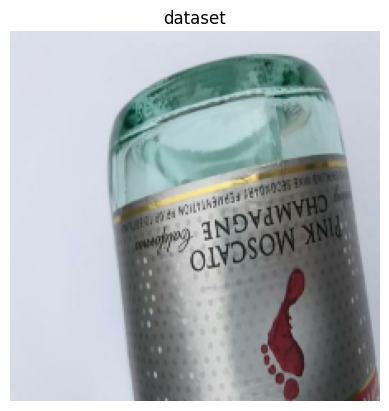

In [6]:
import matplotlib.pyplot as plt

for images,labels in train_ds.take(1):
  plt.imshow(images[0].numpy().astype("uint8"))
  plt.title(class_names[labels[0]])
  plt.axis("off")


In [7]:
import json
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from PIL import Image

In [8]:
IMG_SIZE=(224,224)
BATCH_SIZE=128
SEED=100


In [9]:
DATA_DIR=os.path.join(dataset_path, "dataset")

## 2.SEPARAR LOS DATOS DE ENTRENAMIENTO Y LOS DE PRUEBA

In [10]:
train_data_path=os.path.join(DATA_DIR, "Training")
val_data_path=os.path.join(DATA_DIR, "Testing")


In [11]:
train_ds=tf.keras.preprocessing.image_dataset_from_directory(
    train_data_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED
)

Val_ds=tf.keras.preprocessing.image_dataset_from_directory(
    val_data_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED
)

class_names=train_ds.class_names
print("CLASES DETECTADAS", class_names)

Found 2508 files belonging to 6 classes.
Found 464 files belonging to 6 classes.
CLASES DETECTADAS ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


## 3.Ver algunas imagenes

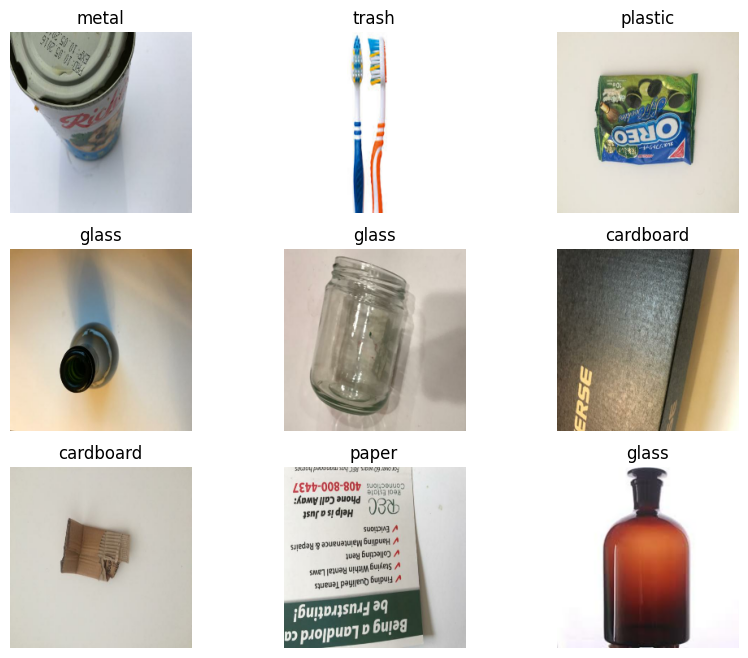

In [12]:
plt.figure(figsize=(10,8))
for images,labels in train_ds.take(1):
  for i in range(9):
    ax=plt.subplot(3,3,i+1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.show()

## 4.Preparar el data set

In [13]:
AUTOTUNE=tf.data.AUTOTUNE

preprocess_input=tf.keras.applications.mobilenet_v2.preprocess_input

train_ds=train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
Val_ds=Val_ds.cache().prefetch(buffer_size=AUTOTUNE)


## 5.Cargar el modelo MobilenetV2

In [14]:
base_model=tf.keras.applications.MobileNetV2(input_shape=(224,224,3),
                                               include_top=False,
                                               weights="imagenet")
base_model.trainable=False

inputs=tf.keras.Input(shape=(224,224,3))
x=preprocess_input(inputs)
x=base_model(x, training=False)
x=tf.keras.layers.GlobalAveragePooling2D()(x)
outputs=tf.keras.layers.Dense(len(class_names), activation="softmax")(x)

model=tf.keras.Model(inputs, outputs)

model.compile(optimizer="adam",
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=["accuracy"])

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6.Entrenar

In [15]:
EPOCHS=2
callback=[
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )


 ]

history=model.fit(
    train_ds,
    validation_data=Val_ds,
    epochs=EPOCHS,
    callbacks=callback
)

Epoch 1/2
20/20 ━━━━━━━━━━━━━━━━━━━━ 144s 6s/step - accuracy: 0.4533 - loss: 1.3820 - val_accuracy: 0.6056 - val_loss: 1.0201
Epoch 2/2
20/20 ━━━━━━━━━━━━━━━━━━━━ 125s 6s/step - accuracy: 0.7368 - loss: 0.7589 - val_accuracy: 0.7155 - val_loss: 0.7991


## 7.Guardar el modelo


In [16]:
OUTPUT_DIR=Path("modelo_reciclaje_mobilenet")
OUTPUT_DIR.mkdir(exist_ok=True)

model.save(OUTPUT_DIR/"waste_mobilenet.h5")
model.save(OUTPUT_DIR/ "waste_mobilenet.keras")

with open(OUTPUT_DIR/"class_names.json", "w",encoding="utf-8") as f:
  json.dump(class_names, f, indent=2)

print("Modelo guardado en:", OUTPUT_DIR/"waste_mobilenet.h5")
print("Modelo guardado en:", OUTPUT_DIR/"waste_mobilenet.keras")
print("Nombres de clases guardados en:", OUTPUT_DIR/"class_names.json")

Modelo guardado en: modelo_reciclaje_mobilenet/waste_mobilenet.h5
Modelo guardado en: modelo_reciclaje_mobilenet/waste_mobilenet.keras
Nombres de clases guardados en: modelo_reciclaje_mobilenet/class_names.json


## 8.Probar nuestro modelo pre-entrenado con una imagen que nunca haya visto

Vidrio: 33.92%
Cartón: 25.25%
Metal: 17.37%


(np.float64(-0.5), np.float64(414.5), np.float64(739.5), np.float64(-0.5))

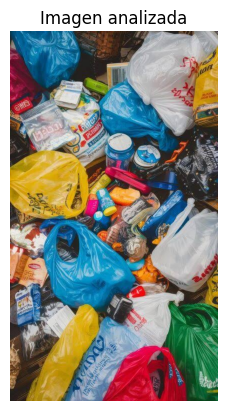

In [18]:
LABELS_ES = {
    "cardboard": "Cartón",
    "glass": "Vidrio",
    "metal": "Metal",
    "paper": "Papel",
    "plastic": "Plástico",
    "trash": "Basura",
}


def predict_image(img_path_param):
    img = Image.open(img_path_param).convert("RGB").resize(IMG_SIZE)
    arr = np.array(img, dtype=np.float32) / 255.0
    arr = np.expand_dims(arr, axis=0)
    preds = model.predict(arr, verbose=0)[0]
    top3_idx = np.argsort(preds)[-3:][::-1]
    for idx in top3_idx:
        raw = class_names[idx]
        print(f"{LABELS_ES.get(raw, raw)}: {preds[idx]*100:.2f}%")
    return class_names[np.argmax(preds)]

# Ejemplo cargando una imagen que el modelo no ha visto:
example_img_path = "basura.jpg"
predict_image(example_img_path)
plt.imshow(Image.open(example_img_path));
plt.title("Imagen analizada");
plt.axis("off")